# Day 6: Drug-Gene Interaction Analysis Using DGIdb

## Project
TNBC Gene Expression Analysis and Biomarker Prioritization

## Objective
To investigate whether the 15 prioritized candidate genes have reported drug-gene interactions using the Drug-Gene Interaction Database (DGIdb).

## Analysis steps
1. Load the DGIdb interaction results.
2. Explore drug-gene interactions.
3. Summarize interaction counts for the 15 candidate genes.
4. Visualize the results.
5. Discuss findings and limitations.

In [1]:
import pandas as pd

# Load DGIdb interaction results
dgidb = pd.read_csv(
    "/content/gene interaction results.tsv",
    sep="\t"
)

# Display the first five rows
dgidb.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/gene interaction results.tsv'

In [2]:
import os

# Show all files uploaded to Colab
os.listdir("/content")

['.config', 'gene_interaction_results-11_22_2026.tsv', 'sample_data']

In [3]:
import pandas as pd

dgidb = pd.read_csv(
    "/content/gene_interaction_results-11_22_2026.tsv",
    sep="\t"
)

print("Dataset shape:", dgidb.shape)

dgidb.head()

Dataset shape: (47, 5)


,gene,drug,regulatory approval,indication,interaction score
0,ELK1,GANCICLOVIR,Approved,NaN,11.705684
1,TNNI2,TIRASEMTIV,Not Approved,NaN,7.803789
2,TNNI2,RELDESEMTIV,Not Approved,NaN,7.803789
3,GRIK3,TOPIRAMATE,Approved,"Anticonvulsants; anti-migraine agents,antimigr...",0.192686
4,GRIK3,SELURAMPANEL,Not Approved,"antimigraine agent,anticonvulsant",0.578058


In [4]:
# Our 15 candidate genes
candidate_genes = [
    "FZD9", "SKA1", "KCNQ4", "ORC1", "DLX5",
    "TNNI2", "IL5RA", "CCDC170", "CCDC96", "ELK1",
    "FFAR4", "GRIK3", "DEFB132", "TDRD10", "EMID1"
]

# Count drug interactions for each gene
gene_counts = (
    dgidb["gene"]
    .value_counts()
    .reindex(candidate_genes, fill_value=0)
)

# Create a summary table
gene_summary = gene_counts.reset_index()
gene_summary.columns = ["Gene", "Interaction_Count"]

# Display results
gene_summary

,Gene,Interaction_Count
0,FZD9,0
1,SKA1,0
2,KCNQ4,21
3,ORC1,0
4,DLX5,0
5,TNNI2,2
6,IL5RA,3
7,CCDC170,0
8,CCDC96,0
9,ELK1,1


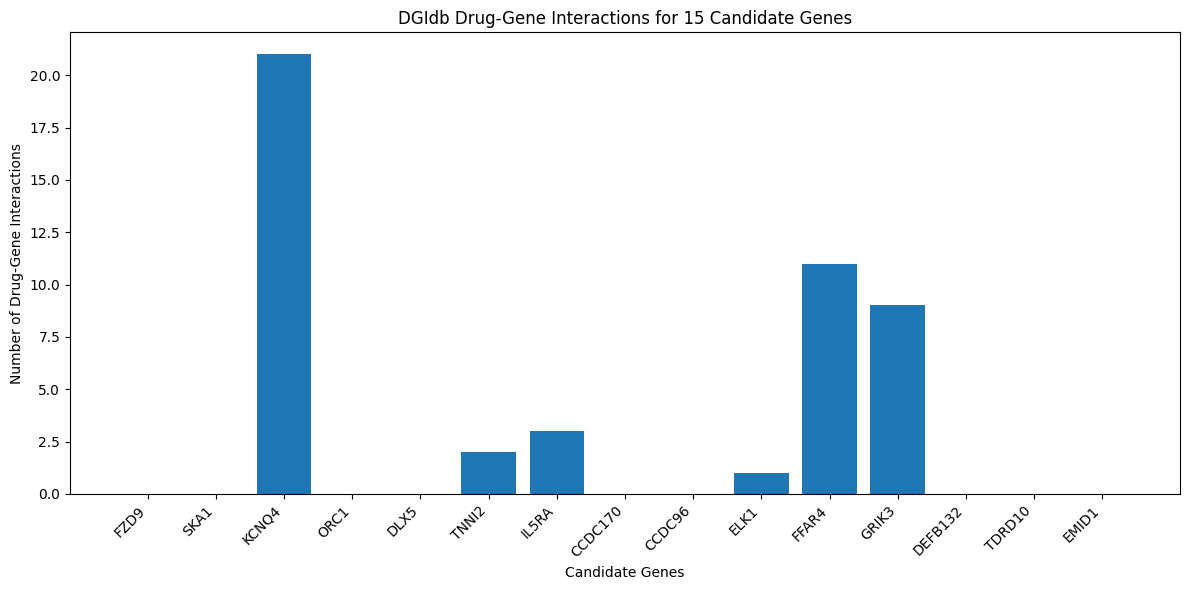

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    gene_summary["Gene"],
    gene_summary["Interaction_Count"]
)

plt.title("DGIdb Drug-Gene Interactions for 15 Candidate Genes")
plt.xlabel("Candidate Genes")
plt.ylabel("Number of Drug-Gene Interactions")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("dgidb_gene_interaction_counts.png", dpi=300)

plt.show()

In [6]:
gene_summary.to_csv(
    "dgidb_gene_interaction_summary.csv",
    index=False
)

print("Day 6 summary saved successfully!")

Day 6 summary saved successfully!


In [7]:
dgidb.to_csv(
    "dgidb_all_interactions.csv",
    index=False
)

print("All 47 interaction records saved successfully!")

All 47 interaction records saved successfully!
